In [1]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_13/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Семинар 2. Foundation-модели на практике: библиотеки и агенты

В первом семинаре мы разобрали, как foundation-модель устроена и как её обучают. Сегодня смотрим на неё глазами пользователя:

- какие модели есть сейчас и как их сравнивать;
- как получить прогноз с ковариатами за пару строк и через какие библиотеки это делают;
- где на этом пути легко ошибиться;
- что могут LLM-агенты: выбирать модель за нас, переводить текст в признаки, проводить исследования.

План:

0. установка;
1. карта моделей;
2. Chronos-2 напрямую: ковариаты и cross-learning;
3. те же модели через библиотеки;
4. ловушки;
5. агенты;
6. итоги.

Продолжение в отдельном ноутбуке «Бустинг против foundation-модели»: когда градиентный бустинг с бизнес-признаками точнее Chronos-2, почему ковариаты в foundation-модели работают не так явно, как хотелось бы, и как объяснять прогнозы обеих моделей.

## 0. Установка

**Как работать с ноутбуком.** Все выводы сохранены, поэтому на семинаре ноутбук можно читать, ничего не запуская. Чтобы повторить самому, откройте его в Colab на T4 и выполните ячейки по порядку. Сохранённые выводы получены на машине без GPU, раздел 5 с `gpt-6-luna`. Разделы 1–4 считаются за несколько минут: на T4 без ключа весь ноутбук идёт около 6 минут плюс пара минут на установку пакетов, и цифры совпадают с сохранёнными. С ключом добавляются агент на 48 рядах (5.2, в сохранённом прогоне меньше минуты) и TimeCopilot (5.4, около 4 минут).

В Colab нужен GPU: **Runtime → Change runtime type → T4 GPU**.

Пакеты с фиксированными версиями ставит первая ячейка ноутбука: в Colab она скачивает `pyproject.toml` занятия, ставит зависимости и перезапускает среду. После перезапуска продолжайте со следующей ячейки. Все пакеты встают поверх torch, который уже есть в Colab.

Есть два пакета, которые мы сознательно не ставим в это окружение:
- **AutoGluon** 1.6 требует torch ниже 2.14, а в Colab стоит более новый, и установка откатила бы его. Как им пользоваться, покажем в разделе 3 без запуска;
- **TimeCopilot** (раздел 5.4) тоже тянет свою версию torch и около 4 ГБ зависимостей. Его ставим в отдельное окружение в фоне, установка занимает пару минут.

In [2]:
# TimeCopilot ставим в отдельное окружение в фоне: у него свои версии torch и scikit-learn
import os
import subprocess
import sys
from pathlib import Path

TC_ENV = Path("tc-env")
TC_LOG = open("tc-install.log", "w")  # noqa: SIM115, лог пишет фоновая установка
if not (TC_ENV / "bin" / "python").exists():
    # В Colab задано UV_SYSTEM_PYTHON=true: без явного --python и сброса этой переменной uv поставил бы
    # TimeCopilot в системный Python и заменил torch прямо в работающей сессии
    uv_env = {**os.environ, "UV_SYSTEM_PYTHON": "false"}
    uv_env.pop("VIRTUAL_ENV", None)
    tc_install = subprocess.Popen(
        f"{sys.executable} -m pip install -q uv && "
        f"{sys.executable} -m uv venv -q --python {sys.executable} {TC_ENV} && "
        # torch для CPU: модели TimeCopilot по умолчанию статистические, GPU им не нужен, а установка в 4 раза быстрее
        f"{sys.executable} -m uv pip install -q --python {TC_ENV}/bin/python --torch-backend cpu timecopilot==0.0.41",
        shell=True,
        stdout=TC_LOG,
        stderr=subprocess.STDOUT,
        env=uv_env,
    )
    print("установка TimeCopilot запущена в фоне")

Ключ OpenAI нужен только в разделе 5. В Colab его удобно положить в секреты (значок ключа слева) под именем `OPENAI_API_KEY`, вне Colab задать переменной окружения. Без ключа ноутбук пропустит раздел 5. Модель берём одну из самых дешёвых среди тех, что умеют вызывать функции: `gpt-6-luna`, $0.10 за миллион входных токенов и $0.50 за миллион выходных. Весь раздел 5 стоит несколько центов.

Если Colab спросит, дать ли ноутбуку доступ к секрету `HF_TOKEN`, можно нажать **Cancel**: все данные и веса публичные.

In [3]:
import json
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
for name in ("lightning", "lightning.pytorch", "pytorch_lightning", "darts", "httpx"):
    logging.getLogger(name).setLevel(logging.ERROR)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(
    f"Python {sys.version.split()[0]}, torch {torch.__version__}, device {DEVICE}",
    torch.cuda.get_device_name() if DEVICE == "cuda" else "",
)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

LLM = os.environ.get("SEMINAR_LLM", "gpt-6-luna")
if not os.environ.get("OPENAI_API_KEY"):
    try:
        from google.colab import userdata

        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:  # не Colab или секрета нет
        pass
HAS_LLM = bool(os.environ.get("OPENAI_API_KEY"))
print(
    "LLM:",
    LLM
    if HAS_LLM
    else "нет ключа, раздел 5 будет пропущен. "
    "Добавьте секрет OPENAI_API_KEY (значок ключа слева) и выполните эту ячейку ещё раз",
)


def mase(history, actual, forecast, season):
    # MASE: средняя ошибка прогноза, делённая на ошибку сезонного наивного прогноза внутри истории
    season = max(season, 1)
    scale = np.mean(np.abs(history[season:] - history[:-season]))
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast))) / max(scale, 1e-8))

Python 3.13.12, torch 2.14.1+cu130, device cpu 
LLM: gpt-6-luna


## 1. Карта моделей

Моделей уже несколько десятков, и каждую неделю появляются новые. Сравнивают их на двух открытых бенчмарках:

- [**GIFT-Eval**](https://huggingface.co/spaces/Salesforce/GIFT-Eval) (Salesforce): 97 конфигураций из 23 датасетов, только история ряда, без ковариат. Мы пользовались им в первом семинаре;
- [**fev-bench**](https://huggingface.co/spaces/autogluon/fev-bench) (Amazon): 100 задач, в 46 из них есть ковариаты, от 1 до 20 окон прогноза на задачу.

У fev-bench результаты каждой модели лежат в репозитории в виде CSV, поэтому лидерборд можно собрать самим за несколько секунд. Метрика задачи: SQL (scaled quantile loss), квантильная потеря, нормированная, как в MASE, на ошибку сезонного наивного прогноза на истории ряда. Затем ошибку модели делят на ошибку Seasonal Naive на той же задаче. Дальше считаются две сводки:
- **skill score** $= 1 - $ геометрическое среднее относительной ошибки: 0.5 значит, что ошибка вдвое меньше, чем у Seasonal Naive;
- **win rate**: доля попарных сравнений с другими моделями, которые модель выиграла по задачам. Зависит от того, какие модели взяли в таблицу. Официальный лидерборд сортирует именно по нему.

In [4]:
import fev

# фиксируем коммит репозитория fev от 11.11.2026, чтобы таблица не менялась от запуска к запуску
FEV_RESULTS = "https://raw.githubusercontent.com/autogluon/fev/9cf943c388e5cfaf352175ea3c69e408b197d997/benchmarks/fev_bench/results/"
FEV_MODELS = [
    "seasonal_naive",
    "autoets",
    "autoarima",
    "stat_ensemble",
    "tft",
    "chronos-bolt",
    "chronos-2",
    "timesfm-2_5",
    "timesfm-3",
    "tirex",
    "tirex-2",
    "moirai-2_0",
    "toto-2_0-22m",
    "toto-2_0-2_5b",
    "sundial-base",
    "simons-25m",
    "simons-297m",
    "timestral-5m",
    "timestral-209m",
    "timeh2o-v1",
    "t0-gamma",
    "ci-proto",
]
summaries = pd.concat([pd.read_csv(FEV_RESULTS + name + ".csv") for name in FEV_MODELS])
board = fev.leaderboard(
    summaries,
    baseline_model="Seasonal Naive",
    missing_strategy="impute",
    leakage_imputation_model="Chronos-Bolt",
    n_resamples=1000,
)
board = board.sort_values("skill_score", ascending=False)
board[
    [
        "skill_score",
        "skill_score_lower",
        "skill_score_upper",
        "win_rate",
        "median_inference_time_s",
        "training_corpus_overlap",
    ]
].round(3)

,skill_score,skill_score_lower,skill_score_upper,win_rate,median_inference_time_s,training_corpus_overlap
model_name,,,,,,
ci-proto,0.515,0.471,0.561,0.855,2.389,0.00
timeh2o-v1,0.508,0.462,0.554,0.859,6.058,0.00
Timestral-209M,0.504,0.457,0.550,0.828,3.590,0.00
t0-gamma,0.494,0.450,0.541,0.776,16.254,0.00
timesfm-3,0.490,0.445,0.537,0.713,20.513,0.00
Simons-297M,0.484,0.438,0.534,0.763,3.904,0.00
Simons-25M,0.477,0.435,0.524,0.670,2.650,0.00
Chronos-2,0.473,0.427,0.521,0.613,2.661,0.00
Timestral-5M,0.462,0.416,0.510,0.603,0.308,0.00


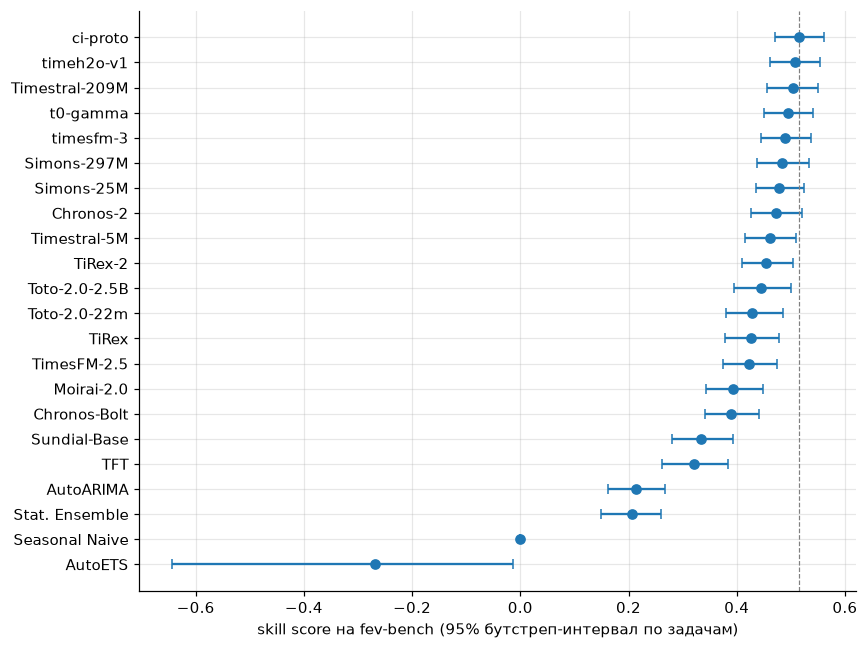

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(board))[::-1]
ax.errorbar(
    board.skill_score,
    y,
    xerr=[board.skill_score - board.skill_score_lower, board.skill_score_upper - board.skill_score],
    fmt="o",
    capsize=3,
)
ax.set_yticks(y, board.index)
ax.axvline(board.skill_score.iloc[0], color="gray", ls="--", lw=0.8)
ax.set_xlabel("skill score на fev-bench (95% бутстреп-интервал по задачам)")
fig.tight_layout()

Что видно на графике:

- **верх таблицы плотный**: у первых десяти моделей skill score от 0.455 до 0.515, и все их интервалы перекрываются. Даже первое место зависит от сводки: по skill score первая ci-proto, по win rate TimeH2O. Разница в одну-две позиции ничего не говорит о вашей задаче;
- **размер решает меньше, чем рецепт**: Timestral-5M почти догоняет Chronos-2 на 120M, а Toto-2.0 на 2.5B параметров ниже десяти моделей, самая большая из которых 331M;
- **все foundation-модели выше всех статистических и обученных под задачу**, включая TFT, который на каждую задачу обучали заново (медианное время обучения около часа). AutoETS в среднем хуже Seasonal Naive: на части задач он ошибается катастрофически, а геометрическое среднее это сильно штрафует;
- **колонка `training_corpus_overlap`**: доля задач, данные которых модель видела при обучении. Её заполняют сами авторы моделей. Для таких задач лидерборд подставляет результат Chronos-Bolt (`leakage_imputation_model`);
- **лидерборд быстро меняется**: ci-proto добавили в fev-bench 11 ноября 2026, за неделю до семинара. Статьи о ней нет, данные обучения не раскрыты.

Карта моделей на ноябрь 2026 (по карточкам моделей на Hugging Face и их репозиториям):

| Модель | Кто | Параметров | Лицензия весов | Ковариаты |
|---|---|---|---|---|
| Chronos-2 | Amazon | 120M | Apache-2.0 | прошлые, известные будущие, многомерные ряды |
| TimesFM-2.5 | Google | 200M + 30M квантильная голова | Apache-2.0 | только через внешнюю регрессию |
| TimesFM-3 | Google | 331M | некоммерческая, для коммерческого использования нужна отдельная лицензия Google | прошлые, будущие, многомерные |
| TiRex-2 | NXAI | 83M | Apache-2.0 | прошлые, будущие, многомерные |
| Toto-2.0 | Datadog | 4M – 2.5B | Apache-2.0 | многомерные ряды, ковариаты в планах |
| Moirai-2.0 | Salesforce | 11M | CC-BY-NC-4.0, некоммерческая | нет |
| Simons | Abel AI Lab | 25M – 297M | OpenMDW-1.1 | будущие, многомерные |
| Timestral | Mistral | 5M – 209M | модифицированная MIT: нельзя, если месячная выручка компании больше $20M | прошлые, будущие, многомерные |
| TimeH2O-v1 | H2O.ai | 108M | некоммерческая | только будущие |
| t0-gamma | The Forecasting Company | 256M | Apache-2.0 | прошлые, будущие, многомерные |
| ci-proto | Continuous Intelligence | 167M | своя, на основе Apache-2.0: при внешнем использовании обязательны упоминание и разовое уведомление авторов | прошлые, будущие, многомерные (по карточке; кода и статьи нет) |

Для продакшена это важнее места в таблице: из первых пяти по skill score без ограничений можно использовать только t0-gamma, а у ci-proto есть условия. Открытые данные и код обучения есть у Simons (кроме закрытой трети корпуса). У Chronos-2 известен список реальных датасетов и открыт код дообучения, синтетические данные не опубликованы.

## 2. Chronos-2 напрямую

Берём Chronos-2: это не лидер, но модель с открытой лицензией, поддержкой всех видов ковариат и самой зрелой библиотекой. Данные: ежедневное число пассажиров общественного транспорта Мадрида (метро, городские автобусы, пригородные автобусы, электрички) с января 2023 по декабрь 2024. Прогнозируем последние 28 дней.

715 дней, 2023-01-01 – 2024-12-15, тест с 2024-11-18


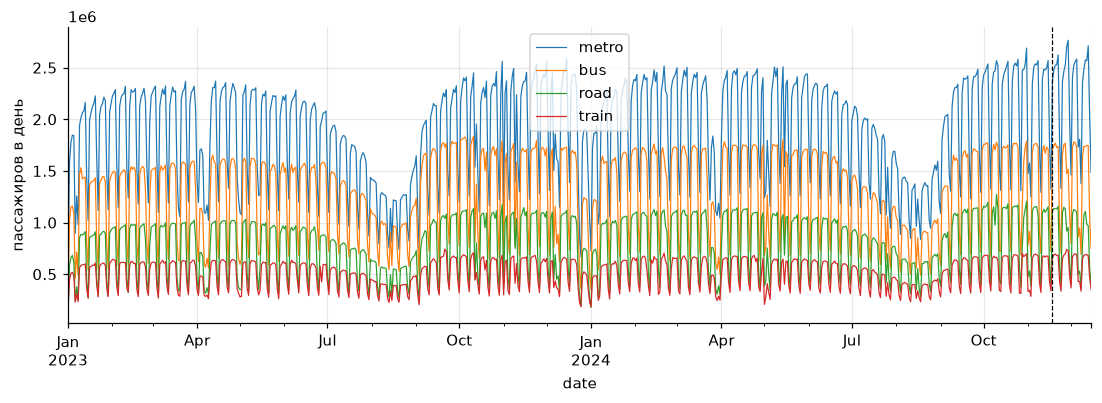

In [6]:
from skforecast.datasets import fetch_dataset

H = 28
raw = fetch_dataset("public_transport_madrid", verbose=False).astype("float32")
data = raw.drop(columns="total")  # total, сумму всех видов транспорта, используем в разделе 4
train, test = data.iloc[:-H], data.iloc[-H:]
print(
    f"{len(data)} дней, {data.index[0].date()} – {data.index[-1].date()}, тест с {test.index[0].date()}"
)

ax = data.plot(figsize=(12, 3.5), lw=0.8)
ax.axvline(test.index[0], color="k", ls="--", lw=0.8)
ax.set_ylabel("пассажиров в день");

Chronos-2 принимает таблицу в длинном формате: колонки `item_id`, `timestamp`, `target`. Все остальные колонки модель считает ковариатами. Если колонка есть и в истории, и в `future_df`, это **известная будущая ковариата** (праздники, цены, прогноз погоды), если только в истории, то **прошлая** (её значения в будущем неизвестны).

Внутри модели каждая такая колонка становится отдельной строкой группы. В каждом из 12 блоков модель сначала смешивает патчи внутри строки (time attention), затем строки группы в одном и том же патче (group attention):

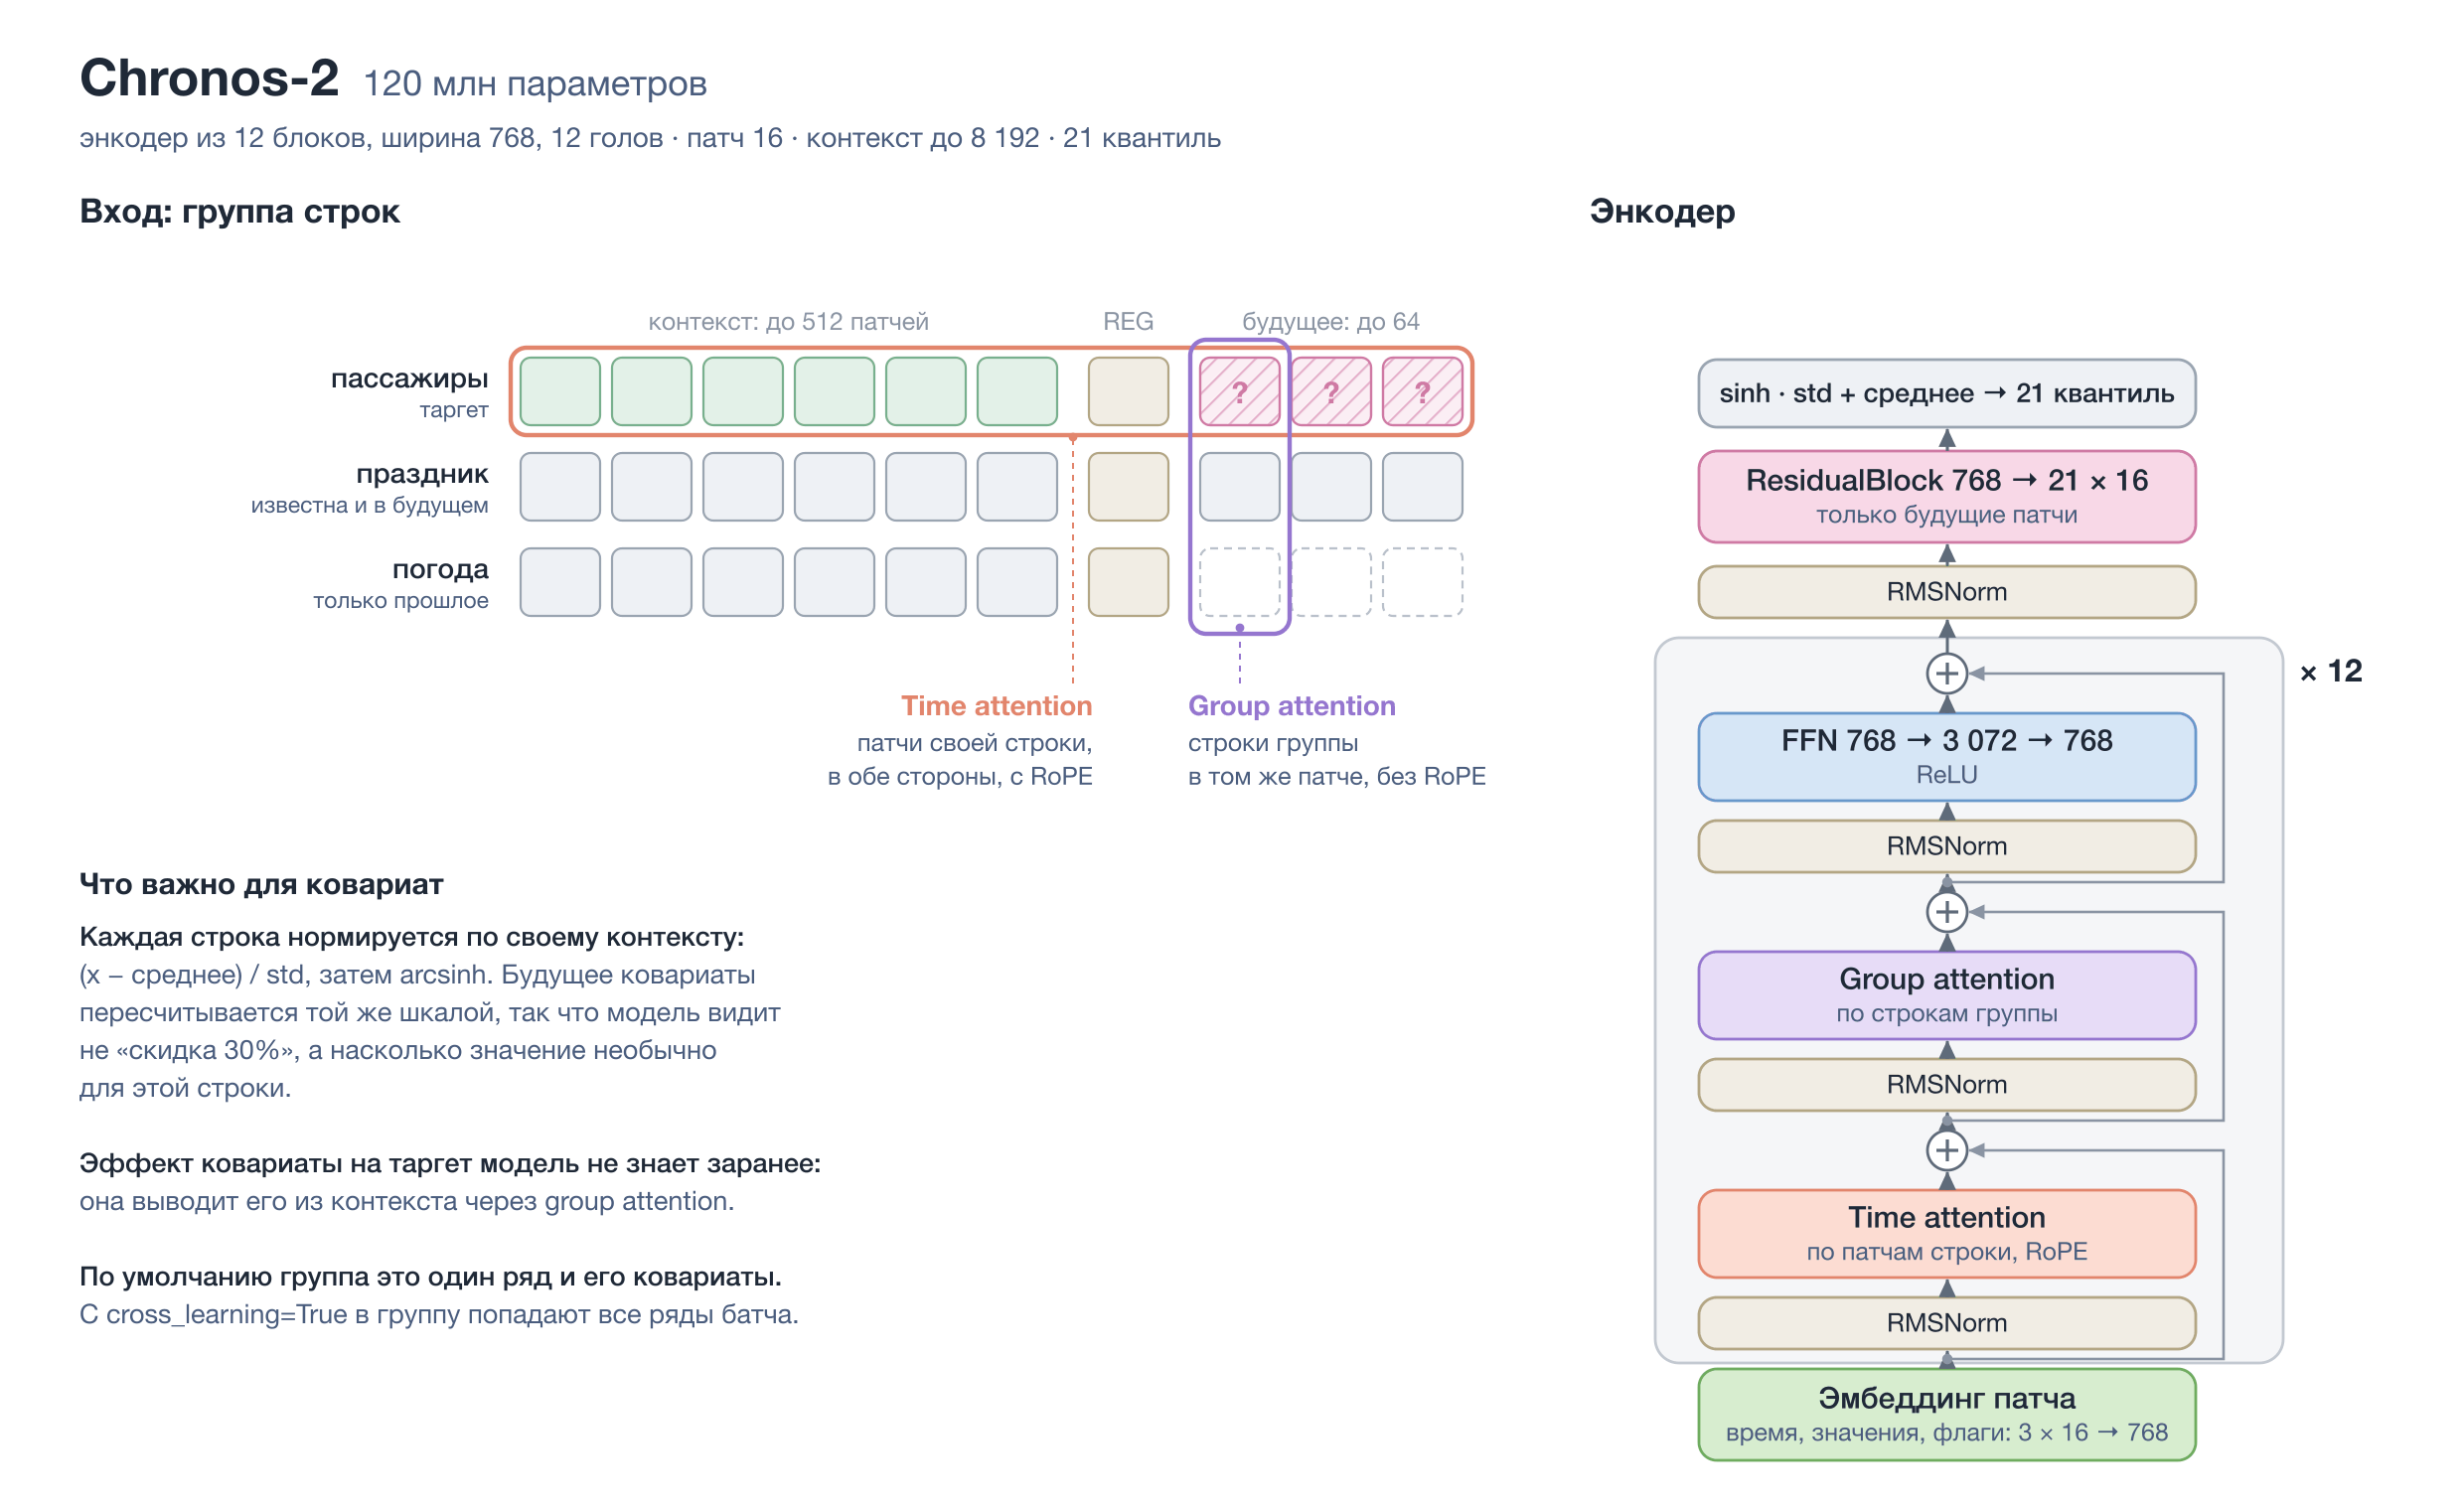

На выходе медиана (`predictions`) и квантили. Модель обучена на 21 квантиле от 0.01 до 0.99, просить можно любые из них.

In [7]:
from chronos import Chronos2Pipeline


def to_long(wide):
    return (
        wide.rename_axis("timestamp")
        .reset_index()
        .melt("timestamp", var_name="item_id", value_name="target")
    )


def score(pred, label):
    # MASE по каждому ряду с сезонностью 7 дней
    wide = pred.pivot(index="timestamp", columns="item_id", values="predictions")
    return {c: mase(train[c].values, test[c].values, wide[c].values, 7) for c in data.columns}


pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
QUANTILES = [0.1, 0.5, 0.9]
results = {}
start = time.time()
pred_uni = pipe.predict_df(to_long(train), prediction_length=H, quantile_levels=QUANTILES)
print(f"4 ряда за {time.time() - start:.1f} с")
results["Chronos-2"] = score(pred_uni, "Chronos-2")
pred_uni.head()

4 ряда за 0.2 с


,item_id,timestamp,target_name,predictions,0.1,0.5,0.9
0,metro,2024-11-18,target,2507573.75,2255123.75,2507573.75,2581349.5
1,metro,2024-11-19,target,2530473.00,2374221.50,2530473.00,2606572.0
2,metro,2024-11-20,target,2321086.25,1867613.25,2321086.25,2521468.0
3,metro,2024-11-21,target,2476362.75,2143278.00,2476362.75,2581366.5
4,metro,2024-11-22,target,2487417.75,2194559.00,2487417.75,2573292.5


Для сравнения два классических бейзлайна из statsforecast: сезонный наивный прогноз и AutoETS с недельной сезонностью.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive

sf_df = to_long(train).rename(columns={"item_id": "unique_id", "timestamp": "ds", "target": "y"})
sf_pred = StatsForecast(
    models=[SeasonalNaive(season_length=7), AutoETS(season_length=7)], freq="D"
).forecast(df=sf_df, h=H)
for model in ("SeasonalNaive", "AutoETS"):
    results[model] = {
        c: mase(train[c].values, test[c].values, sf_pred[sf_pred.unique_id == c][model].values, 7)
        for c in data.columns
    }
pd.DataFrame(results).T.assign(mean=lambda t: t.mean(axis=1)).round(3)

,metro,bus,road,train,mean
Chronos-2,0.776,0.903,1.129,0.956,0.941
SeasonalNaive,0.652,0.607,0.859,0.547,0.666
AutoETS,0.676,0.584,0.810,0.509,0.645


На этом окне Chronos-2 хуже и сезонного наивного прогноза, и AutoETS. Одно окно в 28 дней мало что значит: в разделе 3 проверим на шести окнах.

**Cross-learning.** По умолчанию каждый ряд прогнозируется независимо. С `cross_learning=True` все ряды батча обрабатываются вместе: внимание идёт и по времени, и между рядами (group attention на схеме выше). Здесь это четыре вида транспорта одного города, у них общие праздники и общая динамика.

In [9]:
pred_cross = pipe.predict_df(
    to_long(train), prediction_length=H, quantile_levels=QUANTILES, cross_learning=True
)
results["Chronos-2, cross-learning"] = score(pred_cross, "cross")

**Ковариаты.** В тестовом окне есть 6 декабря, День Конституции. Модель про него не знает. Добавим известную будущую ковариату `holiday`: 1 в праздничные дни Мадрида, 0 в остальные. Календарь берём из пакета `holidays`.

Обратите внимание: модель **не обучается** на этой ковариате. Как праздник влияет на пассажиропоток, она понимает из контекста: в истории есть 1 ноября, прошлогоднее 6 декабря, Рождество и другие праздники, и ковариата отмечает их все.

In [10]:
import holidays

madrid = holidays.country_holidays("ES", subdiv="MD", years=data.index.year.unique())
calendar = pd.DataFrame(
    {"holiday": [float(d in madrid) for d in data.index.date]}, index=data.index
)
print("праздники в тестовом окне:", [d.date() for d in test.index if d.date() in madrid])


def with_calendar(wide, keep_target=True):
    long = to_long(wide).merge(calendar.rename_axis("timestamp").reset_index(), on="timestamp")
    return long if keep_target else long.drop(columns="target")


pred_hol = pipe.predict_df(
    with_calendar(train),
    future_df=with_calendar(test, keep_target=False),
    prediction_length=H,
    quantile_levels=QUANTILES,
)
results["Chronos-2 + праздники"] = score(pred_hol, "holidays")
pd.DataFrame(results).T.assign(mean=lambda t: t.mean(axis=1)).round(3)

праздники в тестовом окне: [datetime.date(2024, 12, 6)]


,metro,bus,road,train,mean
Chronos-2,0.776,0.903,1.129,0.956,0.941
SeasonalNaive,0.652,0.607,0.859,0.547,0.666
AutoETS,0.676,0.584,0.810,0.509,0.645
"Chronos-2, cross-learning",0.782,0.838,1.117,0.916,0.913
Chronos-2 + праздники,0.485,0.486,0.660,0.646,0.569


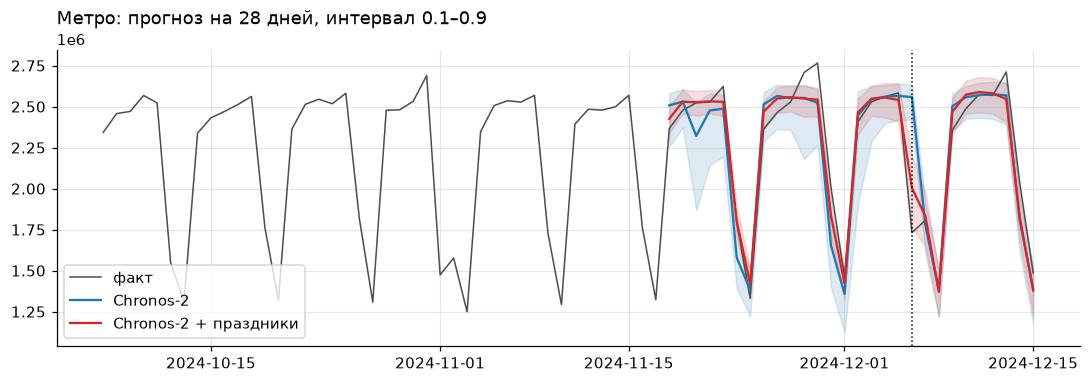

In [11]:
fig, ax = plt.subplots(figsize=(12, 3.5))
shown = data["metro"].iloc[-70:]
ax.plot(shown.index, shown.values, color="0.3", lw=1, label="факт")
for pred, label, color in [
    (pred_uni, "Chronos-2", "C0"),
    (pred_hol, "Chronos-2 + праздники", "C3"),
]:
    p = pred[pred.item_id == "metro"]
    ax.plot(p.timestamp, p["predictions"], color=color, lw=1.5, label=label)
    ax.fill_between(p.timestamp, p["0.1"], p["0.9"], color=color, alpha=0.15)
ax.axvline(pd.Timestamp("2024-12-06"), color="k", ls=":", lw=1)
ax.set_title("Метро: прогноз на 28 дней, интервал 0.1–0.9", loc="left")
ax.legend(loc="lower left");

Cross-learning немного помог (0.913 против 0.941), а одна колонка с праздниками снизила ошибку на 40%, и Chronos-2 обогнал AutoETS. Это главный практический довод за Chronos-2 и модели его поколения: предшественник Chronos-2, Chronos-Bolt, ковариаты не принимал вовсе.

**Дообучение.** У Chronos-2 есть `pipe.fit(...)` с полным дообучением или LoRA (основные веса заморожены, обучаются только небольшие добавочные матрицы низкого ранга). Для четырёх рядов по 700 дней оно бессмысленно, а на сотнях рядов одного бизнеса может заметно помочь; проверять это нужно бэктестом. Для LoRA авторы советуют learning rate около 1e-5. Ещё для LoRA нужен пакет `peft`, в окружение семинара он не входит: без него `fit` с предупреждением переключится на полное дообучение, а предупреждения в этом ноутбуке выключены. Запускается так:

```python
from chronos.chronos2 import preprocess
inputs = preprocess.from_data_frame(long_df, target_columns=["target"], prediction_length=H,
                                    known_covariates_names=["holiday"])
finetuned = pipe.fit(inputs=inputs, prediction_length=H, finetune_mode="lora",
                     learning_rate=1e-5, num_steps=1000, batch_size=32)
```

## 3. Те же модели через библиотеки

Писать обёртку под каждую модель не нужно: основные библиотеки прогнозирования уже умеют работать с foundation-моделями.

| Библиотека | Что умеет | Какие модели |
|---|---|---|
| [Darts](https://unit8co.github.io/darts/) 0.48 | единый интерфейс `fit` / `predict` / `historical_forecasts` | Chronos-2, TimesFM 2.5 и 3, TiRex и TiRex-2, PatchTST-FM, T0 |
| [skforecast](https://skforecast.org) 0.27 | `ForecasterFoundation`, бэктест и подбор параметров | Chronos-2, TimesFM 2.5 и 3, Moirai-2, TiRex-2, TabPFN-TS, Timestral и др. |
| [AutoGluon](https://auto.gluon.ai) 1.6 | AutoML: zero-shot, дообучение и ансамбль со статистическими моделями | Chronos-2, Chronos-Bolt, Toto-2.0 |

### Darts: одна модель меняется одной строкой

В Darts foundation-модели выглядят как обычные нейросетевые модели. `fit` обязателен по интерфейсу, но по умолчанию ничего не обучает: он только проверяет данные и загружает веса. Дообучение включается параметром `enable_finetuning`. Параметр `input_chunk_length` задаёт, сколько истории модель увидит. Ставим всю историю, к этому параметру вернёмся в разделе 4.

In [12]:
from darts import TimeSeries
from darts.models import Chronos2Model, PatchTSTFMModel, TimesFM2p5Model

QUIET = {
    "pl_trainer_kwargs": {
        "enable_progress_bar": False,
        "logger": False,
        "enable_model_summary": False,
    }
}
train_ts = [TimeSeries.from_series(train[c]) for c in data.columns]


def darts_forecast(model_class, context, **kwargs):
    model = model_class(input_chunk_length=context, output_chunk_length=H, **QUIET, **kwargs)
    model.fit(train_ts)
    preds = model.predict(n=H, series=train_ts, verbose=False)
    return {
        c: mase(train[c].values, test[c].values, p.values().ravel(), 7)
        for c, p in zip(data.columns, preds)
    }


darts_results = {}
for name, model_class in [
    ("Chronos-2", Chronos2Model),
    ("TimesFM-2.5", TimesFM2p5Model),
    ("PatchTST-FM", PatchTSTFMModel),
]:
    start = time.time()
    darts_results[name] = darts_forecast(model_class, context=len(train))
    print(f"{name}: {time.time() - start:.0f} с (с загрузкой весов)")
pd.DataFrame(darts_results).T.assign(mean=lambda t: t.mean(axis=1)).round(3)

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


... (12 outputs left out)

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


PatchTST-FM: 1 с (с загрузкой весов)


,metro,bus,road,train,mean
Chronos-2,0.776,0.903,1.129,0.956,0.941
TimesFM-2.5,0.753,0.790,0.860,0.860,0.816
PatchTST-FM,0.641,0.668,0.877,0.949,0.784


Chronos-2 через Darts даёт ровно те же цифры, что напрямую: Darts вызывает ту же модель. TimesFM-2.5 и PatchTST-FM (из её статьи мы брали абляции в первом семинаре) на этом окне лучше Chronos-2 без ковариат, но и они хуже сезонного наивного прогноза. Выбирать модель по одному окну нельзя.

### skforecast: бэктест вместо одного окна

Одно тестовое окно в 28 дней с одним праздником мало что доказывает. Правильнее сделать бэктест: прогнозировать с нескольких точек отсечения подряд и усреднить ошибку. В skforecast это одна функция. Возьмём 6 окон по 28 дней, то есть последние полгода, и сравним Chronos-2 с праздниками и без. Для ориентира посчитаем на тех же окнах сезонный наивный прогноз.

In [13]:
from skforecast.foundation import ForecasterFoundation, FoundationModel, list_adapters
from skforecast.model_selection import TimeSeriesFold, backtesting_foundation

adapters = list_adapters(as_frame=True)
adapters[
    [
        "default_model_id",
        "allow_exog",
        "supports_past_only_covariates",
        "license",
        "commercial_use_restricted",
    ]
]

,default_model_id,allow_exog,supports_past_only_covariates,license,commercial_use_restricted
adapter,,,,,
ChronosAdapter,autogluon/chronos-2-small,True,True,Apache-2.0,False
TimesFM25Adapter,google/timesfm-2.5-200m-pytorch,False,False,Apache-2.0,False
TimesFM3Adapter,google/timesfm-3.0-pytorch,True,True,timesfm-non-commercial-license-v1.0,True
TiRex2Adapter,NX-AI/TiRex-2,True,True,Apache-2.0,False
MoiraiAdapter,Salesforce/moirai-2.0-R-small,False,False,CC-BY-NC-4.0,True
TabICLAdapter,soda-inria/tabicl,True,False,BSD-3-Clause,False
TabPFNAdapter,priorlabs/tabpfn-ts,True,False,tabpfn-3-5-license-v1.0,True
T0Adapter,theforecastingcompany/t0-alpha,True,False,Apache-2.0,False
NoriAdapter,Synthefy/Nori,True,False,Apache-2.0,False


In [14]:
start_bt = len(data) - 6 * H
# для foundation-моделей skforecast игнорирует refit: контекст растёт с каждым окном
cv = TimeSeriesFold(steps=H, initial_train_size=start_bt, refit=False)


def scale(c):
    # знаменатель MASE: ошибка сезонного наивного прогноза на истории до начала бэктеста
    y = data[c].values[:start_bt]
    return np.mean(np.abs(y[7:] - y[:-7]))


naive_errors = []
for c in data.columns:
    y = data[c].values
    for cut in range(start_bt, len(data), H):
        naive = np.tile(y[cut - 7 : cut], H // 7)
        naive_errors.append(np.mean(np.abs(y[cut : cut + H] - naive)) / scale(c))
print(f"{'SeasonalNaive':>13}: MASE (сезонность 7) {np.mean(naive_errors):.3f}")

backtests = {}
for label, exog in [("без ковариат", None), ("+ праздники", calendar)]:
    forecaster = ForecasterFoundation(
        estimator=FoundationModel(model_id="amazon/chronos-2", context_length=2048)
    )
    sk_metric, sk_pred = backtesting_foundation(
        forecaster=forecaster, series=data, exog=exog, cv=cv, metric="mean_absolute_scaled_error"
    )
    backtests[label] = sk_pred
    ours = {}
    for c in data.columns:
        p = sk_pred[sk_pred.level == c]["pred"]
        ours[c] = np.mean(np.abs(data[c].loc[p.index].values - p.values)) / scale(c)
    print(
        f"{label:>13}: MASE (сезонность 7) {np.mean(list(ours.values())):.3f}, "
        f"MASE skforecast {sk_metric.set_index('levels').loc['average'].iloc[0]:.3f}"
    )

SeasonalNaive: MASE (сезонность 7) 1.176


 без ковариат: MASE (сезонность 7) 0.526, MASE skforecast 0.265


  + праздники: MASE (сезонность 7) 0.422, MASE skforecast 0.213


На шести окнах картина другая: Chronos-2 даже без ковариат вдвое точнее сезонного наивного прогноза. В эти полгода попали август, когда пассажиропоток в Мадриде падает, и несколько праздников. Сезонный наивный прогноз на таких переходах ошибается сильно, а Chronos-2 видит прошлый год. Праздники и здесь снижают ошибку ещё на 20%.

И сразу первая ловушка: у skforecast своя MASE, она нормирует на ошибку **несезонного** наивного прогноза (вчерашнее значение), поэтому числа вдвое меньше наших. Сравнивать MASE из разных библиотек нельзя, пока не проверили определение.

### AutoGluon

AutoGluon делает то, что мы делали руками, автоматически: обучает несколько моделей, сравнивает их на валидации и строит из них взвешенный ансамбль. В Colab он требует перезапуска сессии (откатывает torch), поэтому здесь только код:

```python
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
ts = TimeSeriesDataFrame.from_data_frame(with_calendar(data), id_column="item_id", timestamp_column="timestamp")
train_ag, test_ag = ts.train_test_split(H)
predictor = TimeSeriesPredictor(prediction_length=H, known_covariates_names=["holiday"], eval_metric="MASE")
predictor.fit(train_ag, presets="chronos2_ensemble", time_limit=600)
predictor.leaderboard(test_ag)
```

Пресеты: `chronos2` (только zero-shot), `chronos2_ensemble` (zero-shot + дообученная маленькая), `best_quality` (стандартный набор: статистические и табличные модели, TFT, DeepAR, Chronos-2 zero-shot и дообученная маленькая, Toto-2.0-22m). Одна деталь: в AutoGluon у Chronos-2 по умолчанию включён cross-learning, а в самой библиотеке Chronos выключен.

## 4. Ловушки

### 4.1. Модель видит меньше истории, чем вы думаете

В Darts `input_chunk_length` обязательный параметр, и его легко поставить меньше длины истории. Посмотрим, что будет, если поставить 512 дней вместо всей истории (687 дней).

In [15]:
short = darts_forecast(Chronos2Model, context=512)
pd.DataFrame({"вся история (687)": darts_results["Chronos-2"], "512 дней": short}).T.assign(
    mean=lambda t: t.mean(axis=1)
).round(3)

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


,metro,bus,road,train,mean
вся история (687),0.776,0.903,1.129,0.956,0.941
512 дней,1.011,1.201,1.607,1.331,1.287


Модель потеряла первые полгода истории, и ошибка на этом окне выросла больше чем на треть. Никакого предупреждения при этом нет. У каждой модели свой предел контекста (у Chronos-2 8192, у TimesFM-2.5 16 384), и у каждой обёртки своё значение по умолчанию: его надо проверять.

### 4.2. «Известная» ковариата, которая на самом деле неизвестна

Возьмём для метро две ковариаты: число пассажиров городских автобусов и общий пассажиропоток города (колонка `total`, в неё входит и само метро). Каждую передадим двумя способами:
- как **прошлую**: модель видит её только на истории. Так честно, потому что в момент прогноза будущие значения неизвестны;
- как **известную будущую**: передаём её значения на тестовый период в `future_df`.

In [16]:
def metro_with(column, as_future):
    history = raw.loc[train.index, ["metro", column]].rename(columns={"metro": "target"})
    history = history.rename_axis("timestamp").reset_index().assign(item_id="metro")
    future = (
        raw.loc[test.index, [column]].rename_axis("timestamp").reset_index().assign(item_id="metro")
    )
    pred = pipe.predict_df(history, future_df=future if as_future else None, prediction_length=H)
    return mase(train.metro.values, test.metro.values, pred["predictions"].values, 7)


leak = pd.DataFrame(
    {
        "как прошлая": {c: metro_with(c, False) for c in ("bus", "total")},
        "как известная будущая": {c: metro_with(c, True) for c in ("bus", "total")},
    }
)
print(
    f"MASE метро без ковариат {results['Chronos-2']['metro']:.3f}, с праздниками {results['Chronos-2 + праздники']['metro']:.3f}"
)
leak.round(3)

MASE метро без ковариат 0.776, с праздниками 0.485


,как прошлая,как известная будущая
bus,0.785,0.540
total,0.778,0.405


Как прошлые ковариаты автобусы и общий поток ничего не дают: ошибка такая же, как без них. Как «известные будущие» они снижают ошибку почти так же, как честный календарь праздников (автобусы), или даже сильнее (общий поток). Весь этот выигрыш из подсмотренного будущего: в момент прогноза никто не знает, сколько людей поедет на автобусе в следующем месяце. На бэктесте такая модель выглядит лучшей, а в продакшене этих значений не будет.

В жизни так ошибаются с фактической погодой вместо прогноза погоды, с продажами соседнего магазина, с ценой, которую поправили задним числом. Правило: известная будущая ковариата это только то, что вы **знали в момент прогноза**.

### 4.3. Прогноз ряда зависит от соседей по батчу

С `cross_learning=True` модель смотрит на все ряды батча. Значит, прогноз метро зависит от того, какие ещё ряды оказались рядом.

In [17]:
def metro_forecast(columns, cross_learning):
    pred = pipe.predict_df(
        to_long(train[columns]),
        prediction_length=H,
        quantile_levels=QUANTILES,
        cross_learning=cross_learning,
    )
    return pred[pred.item_id == "metro"]["predictions"].values


for cross in (False, True):
    alone, together = metro_forecast(["metro"], cross), metro_forecast(list(data.columns), cross)
    print(
        f"cross_learning={cross}: прогноз метро меняется в среднем на "
        f"{np.mean(np.abs(alone - together)) / train.metro.mean():.2%} от среднего уровня"
    )

cross_learning=False: прогноз метро меняется в среднем на 0.00% от среднего уровня


cross_learning=True: прогноз метро меняется в среднем на 0.35% от среднего уровня


Без cross-learning прогноз метро от соседей не зависит вовсе. С cross-learning зависит, здесь на треть процента. Это немного, и это не ошибка, а свойство: модель пользуется связями между рядами. Но тогда результат зависит от того, какие ряды попали в один батч (`batch_size`, порядок рядов), и бэктест на 100 рядах может не совпасть с прогнозом в продакшене на 10 000. AutoGluon включает cross-learning по умолчанию.

### 4.4. Что ещё проверять

- **Метрика**: MASE из skforecast и наша различаются вдвое (раздел 3). Квантильные метрики (SQL, WQL, CRPS) тоже считают по-разному.
- **Утечка через предобучение**: если модель видела ваш датасет при обучении, zero-shot оценка завышена. Отметки в лидербордах авторы ставят сами. Например, Simons в сабмите на GIFT-Eval заявляет `testdata_leakage: No`, а в обёртке для fev-bench передаёт пустой список `trained_on_datasets`. Проверить это до конца нельзя: больше трети корпуса закрыто. А у Tabby, как мы видели в первом семинаре, docstring и `training_args.json` по-разному описывают, какие данные шли в обучение.
- **Заявления авторов**: в README TimesFM-3 написано «#1 на fev-bench», а в нашей таблице она пятая по skill score и шестая по win rate. ci-proto в своей карточке тоже называет себя первой на fev-bench. Такие заявления верны на день публикации и для выбранной сводки, а устаревают быстрее лидербордов.

## 5. Агенты

**Агент** это LLM, которой дали инструменты (функции) и цикл: модель смотрит на задачу, вызывает инструмент, получает результат, решает, что делать дальше, и так до ответа. Сама LLM ничего не прогнозирует и не считает, она выбирает, какие функции вызвать и с какими аргументами.

Где агентов применяют во временных рядах:
1. **выбор модели**: агент смотрит на ряд и результаты бэктеста и выбирает модель (TimeCopilot, MoiraiAgent от Salesforce);
2. **перевод текста в признаки**: в письме, новости или плане промо есть информация о будущем, агент превращает её в ковариаты;
3. **исследование**: агент предлагает гипотезы, меняет код обучения и ставит эксперименты (так собрали Simons из первого семинара).

Проверим первые два на практике, третий обсудим.

### 5.1. Задача: выбрать модель для ряда

Берём 48 рядов из пяти датасетов fev-bench, на которых Chronos-2, по словам авторов, не обучался: суточные госпитализации, посетители ресторанов, месячное потребление в США, квартальный туризм в Австралии, годовые выбросы CO₂. Для каждого ряда четыре окна прогноза подряд: первые два агент может посмотреть (бэктест), последние два тестовые, их не видит никто.

Кандидатов четыре: SeasonalNaive, AutoETS, AutoTheta и Chronos-2. Все прогнозы считаем заранее, чтобы инструменты агента отвечали мгновенно.

In [18]:
import datasets

AGENT_TASKS = {  # горизонт и сезонность как в fev-bench
    "hospital_admissions_1D": (28, 7),
    "restaurant": (28, 7),
    "us_consumption_1M": (12, 12),
    "australian_tourism": (4, 4),  # в fev-bench 8, но у рядов всего 36 кварталов
    "world_co2_emissions": (5, 1),
}
CANDIDATES = ["SeasonalNaive", "AutoETS", "AutoTheta", "Chronos-2"]
N_WINDOWS = 4  # окна 0-1: бэктест для агента, окна 2-3: тест

rng = np.random.default_rng(0)
pool = {}
for name, (h, s) in AGENT_TASKS.items():
    ds = datasets.load_dataset("autogluon/fev_datasets", name, split="train")
    ok = [
        i
        for i, y in enumerate(ds["target"])
        if len(y) >= N_WINDOWS * h + 3 * max(s, 2) and np.isfinite(np.asarray(y, float)).all()
    ]
    for i in rng.choice(ok, size=min(10, len(ok)), replace=False):
        row = ds[int(i)]
        pool[f"{name}/{row['id']}"] = {
            "dataset": name,
            "H": h,
            "season": s,
            "y": np.asarray(row["target"], float),
        }
print(len(pool), "рядов")

48 рядов


In [19]:
from statsforecast.models import AutoTheta

start = time.time()
window_scores = {sid: {m: [] for m in [*CANDIDATES, "median ensemble"]} for sid in pool}
for name, (h, s) in AGENT_TASKS.items():
    ids = [sid for sid in pool if pool[sid]["dataset"] == name]
    for w in range(N_WINDOWS):
        cut = {sid: len(pool[sid]["y"]) - (N_WINDOWS - w) * h for sid in ids}
        hist = {sid: pool[sid]["y"][: cut[sid]] for sid in ids}
        frame = pd.concat(
            [
                pd.DataFrame({"unique_id": sid, "ds": np.arange(len(v)), "y": v})
                for sid, v in hist.items()
            ]
        )
        stat = StatsForecast(
            models=[
                SeasonalNaive(season_length=s),
                AutoETS(season_length=s),
                AutoTheta(season_length=s),
            ],
            freq=1,
        ).forecast(df=frame, h=h)
        chronos = pipe.predict([torch.tensor(hist[sid]) for sid in ids], prediction_length=h)
        for k, sid in enumerate(ids):
            actual = pool[sid]["y"][cut[sid] : cut[sid] + h]
            preds = {m: stat[stat.unique_id == sid][m].values for m in CANDIDATES[:3]}
            preds["Chronos-2"] = chronos[k][0, chronos[k].shape[1] // 2].numpy()
            preds["median ensemble"] = np.median(np.stack([preds[m] for m in CANDIDATES]), axis=0)
            for m, p in preds.items():
                window_scores[sid][m].append(mase(hist[sid], actual, p, s))
print(f"прогнозы всех моделей на {N_WINDOWS} окнах: {time.time() - start:.0f} с")

backtest_mase = pd.DataFrame(
    {sid: {m: np.mean(v[:2]) for m, v in sc.items()} for sid, sc in window_scores.items()}
).T
test_mase = pd.DataFrame(
    {sid: {m: np.mean(v[2:]) for m, v in sc.items()} for sid, sc in window_scores.items()}
).T
test_mase["argmin backtest"] = [
    test_mase.loc[sid, backtest_mase.loc[sid, CANDIDATES].idxmin()] for sid in test_mase.index
]
test_mase["oracle"] = test_mase[CANDIDATES].min(axis=1)


def geo_mean(x):
    return float(np.exp(np.log(x).mean()))


def summary(table):
    by_dataset = table.groupby([pool[sid]["dataset"] for sid in table.index]).agg(geo_mean)
    return pd.concat([by_dataset, table.agg(geo_mean).to_frame("все 48 рядов").T]).round(3)


summary(test_mase)

прогнозы всех моделей на 4 окнах: 51 с


,SeasonalNaive,AutoETS,AutoTheta,Chronos-2,median ensemble,argmin backtest,oracle
australian_tourism,0.726,0.729,0.713,0.587,0.602,0.640,0.558
hospital_admissions_1D,1.029,0.705,0.738,0.697,0.708,0.703,0.690
restaurant,1.136,0.863,0.867,0.842,0.844,0.861,0.809
us_consumption_1M,1.912,0.901,1.086,0.845,0.932,0.925,0.734
world_co2_emissions,3.566,3.747,3.552,2.835,3.347,3.424,2.606
все 48 рядов,1.440,1.103,1.139,0.975,1.039,1.059,0.912


Геометрическое среднее MASE на тестовых окнах (меньше лучше). Колонки:
- четыре кандидата и их медианный ансамбль;
- `argmin backtest`: правило без всякой LLM, для каждого ряда берём модель с лучшей MASE на двух окнах бэктеста;
- `oracle`: лучшая модель на тесте для каждого ряда. Так выбрать нельзя, это верхняя граница того, что даёт выбор модели.

Между `oracle` и лучшей одиночной моделью есть зазор: выбор модели под ряд **мог бы** помочь. Но правило `argmin backtest` его не ловит и даже проигрывает просто Chronos-2: два окна бэктеста слишком шумные, чтобы надёжно отличить модели. Посмотрим, справится ли LLM.

### 5.2. Агент своими руками

Нам понадобятся три инструмента:
- `describe_series`: статистики истории ряда;
- `backtest`: MASE выбранных моделей на двух окнах бэктеста;
- `submit`: финальный выбор с объяснением.

Инструменты описываются JSON-схемой. Модель отвечает либо текстом, либо вызовом функции с аргументами. Мы выполняем функцию, кладём результат в историю диалога и снова вызываем модель. Это и есть весь агент.

In [20]:
from openai import OpenAI

client = OpenAI() if HAS_LLM else None


def describe_series(series_id):
    d = pool[series_id]
    y = d["y"][: len(d["y"]) - 2 * d["H"]]  # тестовые окна агент не видит
    q = len(y) // 4
    return {
        "dataset": d["dataset"],
        "length": len(y),
        "horizon": d["H"],
        "season_length": d["season"],
        "mean": round(float(y.mean()), 2),
        "std": round(float(y.std()), 2),
        "share_of_zeros": round(float(np.mean(y == 0)), 3),
        "last_quarter_mean_over_first_quarter_mean": round(
            float(y[-q:].mean() / max(abs(y[:q].mean()), 1e-8)), 3
        ),
        "last_values": [round(float(v), 2) for v in y[-12:]],
    }


def backtest(series_id, models):
    return {m: round(float(backtest_mase.loc[series_id, m]), 3) for m in models if m in CANDIDATES}


TOOLS = [
    {
        "type": "function",
        "name": "describe_series",
        "strict": True,
        "description": "Basic statistics of the series history (the test period is hidden).",
        "parameters": {
            "type": "object",
            "properties": {"series_id": {"type": "string"}},
            "required": ["series_id"],
            "additionalProperties": False,
        },
    },
    {
        "type": "function",
        "name": "backtest",
        "strict": True,
        "description": "MASE of the given models on two past windows of the same horizon "
        "(lower is better; 1 = error of the in-sample seasonal naive forecast).",
        "parameters": {
            "type": "object",
            "properties": {
                "series_id": {"type": "string"},
                "models": {"type": "array", "items": {"type": "string", "enum": CANDIDATES}},
            },
            "required": ["series_id", "models"],
            "additionalProperties": False,
        },
    },
    {
        "type": "function",
        "name": "submit",
        "strict": True,
        "description": "Submit the final model for this series. Call exactly once at the end.",
        "parameters": {
            "type": "object",
            "properties": {
                "series_id": {"type": "string"},
                "model": {"type": "string", "enum": CANDIDATES},
                "reason": {"type": "string"},
            },
            "required": ["series_id", "model", "reason"],
            "additionalProperties": False,
        },
    },
]
TOOL_FUNCTIONS = {"describe_series": describe_series, "backtest": backtest}
INSTRUCTIONS = (
    "You are a forecasting assistant. For the given series choose one model from: "
    + ", ".join(CANDIDATES)
    + ". Use the tools to look at the data and past performance, then call submit."
)
# Локальный сервер llama.cpp, на котором ноутбук проверяли без ключа, не принимает обратно блоки reasoning
LOCAL_SERVER = os.environ.get("OPENAI_BASE_URL", "").startswith("http://127.")


def run_agent(series_id, max_turns=6, verbose=False):
    items = [
        {
            "role": "user",
            "content": f"Series id: {series_id}. Pick the model for the next {pool[series_id]['H']} steps.",
        }
    ]
    usage = {"input_tokens": 0, "output_tokens": 0, "requests": 0}
    for _ in range(max_turns):
        response = client.responses.create(
            model=LLM,
            instructions=INSTRUCTIONS,
            tools=TOOLS,
            input=items,
            reasoning={"effort": "low"},
        )
        usage["input_tokens"] += response.usage.input_tokens
        usage["output_tokens"] += response.usage.output_tokens
        usage["requests"] += 1
        items += [it for it in response.output if not (LOCAL_SERVER and it.type == "reasoning")]
        calls = [it for it in response.output if it.type == "function_call"]
        if not calls:  # модель ответила текстом вместо вызова submit
            return None, usage
        for call in calls:
            args = json.loads(call.arguments)
            if verbose:
                print(f"→ {call.name}({args})")
            if call.name == "submit":
                return args, usage
            result = TOOL_FUNCTIONS[call.name](**args)
            if verbose:
                print(f"← {result}")
            items.append(
                {
                    "type": "function_call_output",
                    "call_id": call.call_id,
                    "output": json.dumps(result),
                }
            )
    return None, usage


if HAS_LLM:
    example = "us_consumption_1M/" + next(
        sid.split("/", 1)[1] for sid in pool if sid.startswith("us_consumption")
    )
    choice, usage = run_agent(example, verbose=True)
    print(
        "\nвыбор:",
        choice["model"] if choice else None,
        "\n",
        choice["reason"] if choice else "",
        "\n",
        usage,
    )

→ describe_series({'series_id': 'us_consumption_1M/furnishings_and_durable_household_equipment'})
← {'dataset': 'us_consumption_1M', 'length': 768, 'horizon': 12, 'season_length': 12, 'mean': 151716.17, 'std': 118557.19, 'share_of_zeros': 0.0, 'last_quarter_mean_over_first_quarter_mean': 12.715, 'last_values': [466756.0, 468009.0, 474069.0, 479723.0, 477206.0, 475854.0, 475532.0, 481054.0, 479029.0, 483772.0, 473935.0, 471078.0]}
→ backtest({'series_id': 'us_consumption_1M/furnishings_and_durable_household_equipment', 'models': ['SeasonalNaive', 'AutoETS', 'AutoTheta', 'Chronos-2']})
← {'SeasonalNaive': 5.933, 'AutoETS': 2.011, 'AutoTheta': 3.14, 'Chronos-2': 2.763}


→ submit({'series_id': 'us_consumption_1M/furnishings_and_durable_household_equipment', 'model': 'AutoETS', 'reason': "AutoETS has the lowest backtest MASE (2.011), outperforming Chronos-2, AutoTheta, and SeasonalNaive. The series shows substantial long-run growth, making a fitted level/trend model preferable to repeating last year's seasonal pattern."})

выбор: AutoETS 
 AutoETS has the lowest backtest MASE (2.011), outperforming Chronos-2, AutoTheta, and SeasonalNaive. The series shows substantial long-run growth, making a fitted level/trend model preferable to repeating last year's seasonal pattern. 
 {'input_tokens': 841, 'output_tokens': 195, 'requests': 2}


Теперь запускаем агента на всех 48 рядах. Запросы к API независимы, поэтому шлём их в 8 потоков. LLM отвечает по-разному от запуска к запуску, поэтому токены и обоснования у вас будут другими. Итог при этом почти не меняется: в двух наших прогонах с `gpt-6-luna` он совпал до третьего знака.

In [21]:
from concurrent.futures import ThreadPoolExecutor


def safe_run(sid):
    try:
        return sid, *run_agent(sid)
    except Exception as error:  # один упавший запрос не должен ронять весь прогон
        print(sid, repr(error)[:200])
        return sid, None, {"input_tokens": 0, "output_tokens": 0, "requests": 0}


if HAS_LLM:
    start = time.time()
    with ThreadPoolExecutor(8) as executor:
        runs = list(executor.map(safe_run, pool))
    agent_seconds = time.time() - start
    # без ответа агента берём Seasonal Naive: сбой API не должен улучшать результат агента
    picks = pd.Series(
        {sid: choice["model"] if choice else "SeasonalNaive" for sid, choice, _ in runs}
    )
    agent_usage = pd.DataFrame({sid: u for sid, _, u in runs}).T.sum()
    cost = agent_usage.input_tokens / 1e6 * 0.10 + agent_usage.output_tokens / 1e6 * 0.50
    print(
        f"{agent_seconds:.0f} с, {int(agent_usage.requests)} запросов, {int(agent_usage.input_tokens)} входных и "
        f"{int(agent_usage.output_tokens)} выходных токенов, около ${cost:.3f} по ценам gpt-6-luna"
    )
    print(
        "без ответа:",
        sum(c is None for _, c, _ in runs),
        "| выборы агента:",
        picks.value_counts().to_dict(),
    )
    test_mase["agent"] = [test_mase.loc[sid, picks[sid]] for sid in test_mase.index]
summary(test_mase)

26 с, 101 запросов, 41151 входных и 9283 выходных токенов, около $0.009 по ценам gpt-6-luna
без ответа: 0 | выборы агента: {'Chronos-2': 20, 'AutoETS': 15, 'AutoTheta': 13}


,SeasonalNaive,AutoETS,AutoTheta,Chronos-2,median ensemble,argmin backtest,oracle,agent
australian_tourism,0.726,0.729,0.713,0.587,0.602,0.640,0.558,0.640
hospital_admissions_1D,1.029,0.705,0.738,0.697,0.708,0.703,0.690,0.703
restaurant,1.136,0.863,0.867,0.842,0.844,0.861,0.809,0.862
us_consumption_1M,1.912,0.901,1.086,0.845,0.932,0.925,0.734,0.925
world_co2_emissions,3.566,3.747,3.552,2.835,3.347,3.424,2.606,3.424
все 48 рядов,1.440,1.103,1.139,0.975,1.039,1.059,0.912,1.059


In [22]:
# где агент не согласился с правилом argmin backtest и чем он это объяснил
if HAS_LLM:
    argmin = backtest_mase[CANDIDATES].idxmin(axis=1)
    differ = [(sid, choice) for sid, choice, _ in runs if choice and choice["model"] != argmin[sid]]
    print(f"рядов, где агент разошёлся с argmin backtest: {len(differ)} из {len(pool)}")
    for sid, choice in differ[:6]:
        print(
            f"\n{sid}: argmin {argmin[sid]}, агент {choice['model']}, "
            f"MASE на тесте {test_mase.loc[sid, argmin[sid]]:.3f} против {test_mase.loc[sid, choice['model']]:.3f}\n  {choice['reason']}"
        )

рядов, где агент разошёлся с argmin backtest: 1 из 48

restaurant/air_b9e27558fb8bd5c4: argmin Chronos-2, агент AutoETS, MASE на тесте 0.776 против 0.783
  AutoETS tied for the best backtest MASE (0.84) and is well suited to this weekly seasonal series; it also accommodates the modest longer-term decline. SeasonalNaive performed worse.


Что обсудить:

- куда попал агент относительно `argmin backtest`, Chronos-2 и `oracle`? Ожидаемо он близок к `argmin backtest`: видит ту же информацию и чаще всего просто берёт минимум бэктеста. В сохранённом прогоне с `gpt-6-luna` агент получил 1.059, ровно как правило, в прогонах с открытой моделью `qwen3.8-27b` от 1.046 до 1.059. У Chronos-2 0.975. Посмотрите, на каких рядах и почему он разошёлся с правилом. В сохранённом прогоне расхождение одно, и оно из-за округления: инструмент `backtest` отдаёт MASE с тремя знаками, и агент увидел ничью AutoETS с Chronos-2;
- если сильная модель по умолчанию уже есть, выбирать модель по двум окнам бэктеста вредно, с LLM или без. Нужна или длинная история бэктестов, или другая постановка (ансамбль, взвешивание);
- это совпадает с опубликованными результатами. TimeCopilot заявляет первое место на GIFT-Eval, но в их скрипте для GIFT-Eval LLM нет вовсе: это фиксированный медианный ансамбль Chronos-2, TimesFM-2.5 и TiRex. MoiraiAgent от Salesforce выбирает из тех же трёх моделей с помощью LLM на 3.4 млрд параметров, дообученной на двух миллионах примеров (а если прогнозы моделей почти совпадают, LLM не вызывает вовсе; подробности в [блоге авторов](https://www.salesforce.com/blog/moiraiagent)). По нашему пересчёту файлов лидерборда GIFT-Eval (сабмиты MoiraiAgent и TimeCopilot, это и есть медианный ансамбль) он лучше медианного ансамбля на 1–2% (MASE 0.689 против 0.705, CRPS 0.476 против 0.483) и примерно на столько же лучше одного Chronos-2. Выигрыш есть, но небольшой, и для него понадобилась LLM, специально обученная выбирать модель;
- агент стоит денег и времени и при каждом запуске может выбрать по-разному. Детерминированное правило бесплатно и воспроизводимо.

### 5.3. Где LLM действительно полезна: текст → ковариаты

В разделе 2 праздники мы взяли из пакета `holidays`. Но часто информация о будущем есть только в тексте: новость о забастовке, письмо о плановом закрытии станции, план промоакций. В бенчмарке [Context is Key](https://arxiv.org/abs/2410.18959) (ServiceNow, 71 задача, в которых без текста хороший прогноз не сделать) лучшая LLM, Llama-3.1-405B, с текстом снижает ошибку на 67% и ошибается вдвое меньше, чем Chronos без текста. Но у многих моделей текст почти не помогает, а иногда и вредит.

Проверим идею на нашем метро. Дадим агенту новостную сводку, в которой полезная информация перемешана с лишней, и попросим отметить дни, когда пассажиропоток будет как в выходной. Историю ковариаты (прошлые праздники) берём из календаря: она известна, а вот будущее агент вытаскивает из текста.

In [23]:
NEWS = """Новости Мадрида, 17 ноября 2024.
Городской совет отложил до весны решение о новых тарифах на парковку в центре.
Рождественская иллюминация на улицах включится 28 ноября.
1 декабря на стадионе «Сантьяго Бернабеу» пройдёт матч «Реал» против «Хетафе».
В пятницу, 6 декабря, отмечается День Конституции: государственный выходной, офисы и школы закрыты.
Праздник 8 декабря в этом году выпадает на воскресенье, переноса выходного в Мадриде не будет.
Школьные рождественские каникулы начнутся 21 декабря."""

DAYS_OFF_TOOL = [
    {
        "type": "function",
        "name": "mark_days_off",
        "strict": True,
        "description": "Mark future dates when public transport ridership will look like a Sunday or holiday.",
        "parameters": {
            "type": "object",
            "properties": {
                "dates": {"type": "array", "items": {"type": "string", "description": "YYYY-MM-DD"}}
            },
            "required": ["dates"],
            "additionalProperties": False,
        },
    }
]

if HAS_LLM:
    response = client.responses.create(
        model=LLM,
        tools=DAYS_OFF_TOOL,
        tool_choice="required",
        reasoning={"effort": "low"},
        instructions=f"Forecast period: {test.index[0].date()} to {test.index[-1].date()}. "
        "Read the news and mark weekday dates in that period that will behave like a day off.",
        input=NEWS,
    )
    call = next(it for it in response.output if it.type == "function_call")
    llm_days = sorted(pd.Timestamp(d) for d in json.loads(call.arguments)["dates"])
    print("LLM отметила:", [d.date() for d in llm_days])

    future_calendar = calendar.copy()
    future_calendar.loc[test.index, "holiday"] = [float(d in llm_days) for d in test.index]
    long_hist = to_long(train).merge(
        calendar.rename_axis("timestamp").reset_index(), on="timestamp"
    )
    long_future = (
        to_long(test)
        .drop(columns="target")
        .merge(future_calendar.rename_axis("timestamp").reset_index(), on="timestamp")
    )
    pred_text = pipe.predict_df(
        long_hist, future_df=long_future, prediction_length=H, quantile_levels=QUANTILES
    )
    results["Chronos-2 + даты из текста"] = score(pred_text, "text")
pd.DataFrame(results).T.assign(mean=lambda t: t.mean(axis=1)).round(3)

LLM отметила: [datetime.date(2024, 12, 6)]


,metro,bus,road,train,mean
Chronos-2,0.776,0.903,1.129,0.956,0.941
SeasonalNaive,0.652,0.607,0.859,0.547,0.666
AutoETS,0.676,0.584,0.810,0.509,0.645
"Chronos-2, cross-learning",0.782,0.838,1.117,0.916,0.913
Chronos-2 + праздники,0.485,0.486,0.660,0.646,0.569
Chronos-2 + даты из текста,0.485,0.486,0.660,0.646,0.569


Если LLM отметила только 6 декабря, результат совпадает с календарём из `holidays`. Здесь LLM не прогнозирует ряд: она переводит текст в структуру, которую понимает Chronos-2. Это разделение труда и работает на практике: числами занимается модель для рядов, текстом языковая модель.

### 5.4. TimeCopilot

[TimeCopilot](https://github.com/TimeCopilot/timecopilot) это готовый агент того же устройства, что наш из 5.2, только больше: признаки ряда из `tsfeatures`, кросс-валидация на одном окне, выбор модели, прогноз, поиск аномалий и текстовый отчёт. По умолчанию он выбирает среди 11 статистических моделей и Prophet, foundation-модели подключаются отдельно. Запустим его на метро (установка шла в фоне с начала семинара).

In [24]:
# ждём фоновую установку из раздела 0
if "tc_install" in globals():
    while tc_install.poll() is None:
        print("TimeCopilot ещё ставится...", flush=True)
        time.sleep(20)
    print("код возврата установки:", tc_install.returncode)

TC_SCRIPT = r"""
import json, multiprocessing, sys
import pandas as pd


def main():
    multiprocessing.set_start_method("fork", force=True)  # иначе statsforecast долго запускает процессы
    from timecopilot import TimeCopilot
    df = pd.read_csv(sys.argv[1], parse_dates=["ds"])
    result = TimeCopilot(llm=sys.argv[2], retries=3).forecast(df=df, freq="D", h=int(sys.argv[3]))
    out = result.output.model_dump()
    out["forecast"] = result.fcst_df[result.output.selected_model].tolist()
    out["ds"] = result.fcst_df["ds"].astype(str).tolist()
    out["usage"] = {"input_tokens": result.usage().input_tokens, "output_tokens": result.usage().output_tokens,
                    "requests": result.usage().requests}
    json.dump(out, open(sys.argv[4], "w"), ensure_ascii=False)


if __name__ == "__main__":
    main()
"""
Path("run_timecopilot.py").write_text(TC_SCRIPT)
train.metro.rename_axis("ds").reset_index().rename(columns={"metro": "y"}).assign(
    unique_id="metro"
).to_csv("metro.csv", index=False)

tc_llm = os.environ.get("SEMINAR_TC_LLM", f"openai:{LLM}")
if HAS_LLM:
    start = time.time()
    run = subprocess.run(
        [
            str(TC_ENV / "bin" / "python"),
            "run_timecopilot.py",
            "metro.csv",
            tc_llm,
            str(H),
            "tc.json",
        ],
        capture_output=True,
        text=True,
        env={**os.environ, "MPLBACKEND": "Agg"},
    )  # бэкенд matplotlib из ноутбука в другом окружении не загрузится
    print(f"{time.time() - start:.0f} с, код возврата {run.returncode}")
    if run.returncode != 0:
        print(run.stderr[-2000:])

216 с, код возврата 0


In [25]:
if HAS_LLM and Path("tc.json").exists():
    tc = json.loads(Path("tc.json").read_text())
    for key in ("selected_model", "model_comparison", "reason_for_selection", "forecast_analysis"):
        print(f"--- {key}\n{tc[key]}\n")
    print("токены:", tc["usage"])
    tc_forecast = pd.Series(tc["forecast"], index=pd.to_datetime(tc["ds"])).reindex(test.index)
    results["TimeCopilot: " + tc["selected_model"]] = {
        "metro": mase(train.metro.values, test.metro.values, tc_forecast.values, 7)
    }
pd.DataFrame(results).T.round(3)

--- selected_model
Prophet

--- model_comparison
Cross-validation MASE results (lower is better): Prophet 1.2875; Theta 1.4315; AutoETS 1.4613; AutoCES 1.4821; AutoARIMA 1.5373; SeasonalNaive 2.6869. Prophet had the lowest MASE among the evaluated candidates, about 52% lower than SeasonalNaive (1 - 1.2875/2.6869). Theta was the next best and also substantially outperformed SeasonalNaive. AutoETS, AutoCES, and AutoARIMA were competitive but less accurate than Prophet on these validation results. SeasonalNaive performed worst, suggesting that repeating the last seasonal cycle alone does not capture the trend and changing levels adequately. The supplied results give aggregate MASE values but not per-window scores, so the stability of the ranking across individual validation windows cannot be assessed.

--- reason_for_selection
Prophet was selected because it had the lowest cross-validation MASE (1.2875) among the tested models, and it clearly beat the SeasonalNaive benchmark (2.6869). Its

,metro,bus,road,train
Chronos-2,0.776,0.903,1.129,0.956
SeasonalNaive,0.652,0.607,0.859,0.547
AutoETS,0.676,0.584,0.810,0.509
"Chronos-2, cross-learning",0.782,0.838,1.117,0.916
Chronos-2 + праздники,0.485,0.486,0.660,0.646
Chronos-2 + даты из текста,0.485,0.486,0.660,0.646
TimeCopilot: Prophet,2.129,NaN,NaN,NaN


Что видно:

- TimeCopilot честно сделал кросс-валидацию, но на **одном** окне в 28 дней (так по умолчанию), и выбрал модель по нему. Какие из 12 моделей проверять, решает LLM;
- отчёт звучит убедительно, но проверяйте утверждения. У `gpt-6-luna` в сохранённом выводе он аккуратный. С открытой моделью `qwen3.8-27b` агент каждый раз тоже выбирал Prophet, но в отчётах были ошибки. В одном арифметика неверна: «~47–52% over every alternative», хотя по его же таблице Prophet лучше Theta всего на 10% (1.287 против 1.432). В другом выбор обоснован тем, что Prophet умеет учитывать праздники, хотя праздники в Prophet не передавались. В третьем агент сослался на «все окна кросс-валидации», хотя окно одно, в четвёртом предупредил, что прогноз может сломать День благодарения: американский праздник, к мадридскому метро отношения не имеет;
- на тесте Prophet ошибся сильнее всех, у нас MASE около 2: он занизил уровень будних дней, 2.2 млн пассажиров против 2.5 млн в последние недели истории. Одно окно кросс-валидации этого не поймало;
- весь ряд передаётся в промпт в виде JSON, поэтому на один ряд уходит около 50 тысяч входных токенов у `gpt-6-luna` и вдвое больше у Qwen. На тысячах рядов это заметные деньги.

### 5.5. Агенты как исследователи

Третий сценарий мы видели в первом семинаре: модель Simons собрали агенты. По [описанию авторов](https://abel.ai/research/introducing-simons/):

- две кампании: около двух недель на основную модель и около пяти дней на поддержку ковариат. Всего больше 250 направлений исследования и почти 2000 экспериментов, в основном на маленьких моделях, меньше $8000 на GPU;
- каждое направление проходит цикл из четырёх этапов. Сначала агент предлагает направление. Затем другой агент меняет код обучения и итерирует в фиксированном бюджете вычислений, выбирая лучший вариант только по валидации. Потом лучшего кандидата пересобирают с зафиксированным кодом и переобучают на отложенных seed. В конце выводы записывают в общую базу знаний, чтобы следующие направления их учитывали. Несколько таких циклов идут параллельно;
- агенты не могут менять код оценки и не видят ответы бенчмарка. Цели, правила оценки, данные и вычисления задали люди;
- около трёх четвертей выигрыша первой кампании дали данные и то, как ряд подаётся в модель, а изменения backbone почти ничего.

Именно так устроен nanoTSFM из первого семинара: задача, фиксированный бюджет, честная оценка и рекорды, перепроверенные на трёх seed. Это площадка для таких агентов. Узкое место там не в генерации идей, а в честной оценке: агент, которому разрешено смотреть на тест, быстро «найдёт» улучшение, которого нет.

## 6. Итоги

| вопрос | ответ |
|---|---|
| какую foundation-модель выбрать | лидеры fev-bench и GIFT-Eval отличаются меньше, чем разброс по задачам. Выбирайте по лицензии, поддержке ковариат и удобству, а качество проверяйте бэктестом на своих данных |
| что даёт больше всего | ковариаты, а не выбор модели: одна колонка с праздниками снизила ошибку на 40% на тестовом окне и на 20% на полугодовом бэктесте |
| на что смотреть в библиотеках | у Darts, skforecast и AutoGluon свои значения по умолчанию: длина контекста, cross-learning, определение метрики |
| что такое известная будущая ковариата | только то, что вы знали в момент прогноза |
| может ли LLM-агент выбрать модель | не лучше простого правила «минимум бэктеста» и хуже сильной модели по умолчанию: в наших прогонах около 1.05 против 0.975 у Chronos-2. TimeCopilot выбрал Prophet, худшую модель на тесте |
| где LLM полезна | где есть текст: перевести его в признаки, объяснить результат, ответить на вопрос. И в исследованиях, если оценка честная и закрыта от агента |
| когда бустинг с признаками лучше foundation-модели | разбираем в следующем ноутбуке, «Бустинг против foundation-модели» |

Ссылки:
- лидерборды: [fev-bench](https://huggingface.co/spaces/autogluon/fev-bench), [GIFT-Eval](https://huggingface.co/spaces/Salesforce/GIFT-Eval); пакет [fev](https://github.com/autogluon/fev);
- [Chronos-2](https://github.com/amazon-science/chronos-forecasting): код, статья и ноутбуки с дообучением;
- [Darts](https://unit8co.github.io/darts/), [skforecast](https://skforecast.org), [AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-chronos.html);
- агенты: [TimeCopilot](https://github.com/TimeCopilot/timecopilot), [MoiraiAgent](https://github.com/SalesforceAIResearch/uni2ts/tree/main/project/moirai-agent), [Context is Key](https://arxiv.org/abs/2410.18959), [Are Language Models Actually Useful for Time Series Forecasting?](https://arxiv.org/abs/2406.16964);
- [как агенты собирали Simons](https://abel.ai/research/introducing-simons/).